In [3]:
import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

In [4]:
df = pd.read_csv('../data/METABRIC_RNA_Mutation.csv')

C:\Users\DANISH LAPTOP\AppData\Local\Temp\ipykernel_884\591033886.py:1: DtypeWarning: Columns (0: rasgef1b_mut, 1: hras_mut, 2: smarcb1_mut, 3: siah1_mut) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/METABRIC_RNA_Mutation.csv')


In [5]:
df.head()

,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df.shape

(1904, 693)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Columns: 693 entries, patient_id to siah1_mut
dtypes: float64(498), int64(5), object(4), str(186)
memory usage: 10.1+ MB


In [8]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,1904.0,NaN,NaN,NaN,3921.982143,2358.478332,0.0,896.5,4730.5,5536.25,7299.0
age_at_diagnosis,1904.0,NaN,NaN,NaN,61.087054,12.978711,21.93,51.375,61.77,70.5925,96.29
type_of_breast_surgery,1882,2,MASTECTOMY,1127,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cancer_type,1904,2,Breast Cancer,1903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cancer_type_detailed,1889,6,Breast Invasive Ductal Carcinoma,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
hras_mut,1904.0,4.0,0.0,1024.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prps2_mut,1904,3,0,1902,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smarcb1_mut,1904.0,4.0,0.0,1024.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stmn2_mut,1904,3,0,1902,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
missing = pd.DataFrame({

    'Missing_Count' : df.isnull().sum(),
    'Missing_Percentage' : df.isnull().sum() / len(df) * 100

})

missing = missing[missing['Missing_Count'] > 0].sort_values(
    'Missing_Percentage',
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
tumor_stage,501,26.313025
3-gene_classifier_subtype,204,10.714286
primary_tumor_laterality,106,5.567227
neoplasm_histologic_grade,72,3.781513
cellularity,54,2.836134
mutation_count,45,2.363445
er_status_measured_by_ihc,30,1.575630
type_of_breast_surgery,22,1.155462
tumor_size,20,1.050420
cancer_type_detailed,15,0.787815


In [11]:
outcome_related_cols = [
    c for c in df.columns
    if any(word in c.lower()
           for word in ['survival', 'death', 'status', 'event'])
]

print("Outcome-related columns:")
print(outcome_related_cols)

Outcome-related columns:
['er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'overall_survival_months', 'overall_survival', 'pr_status', 'death_from_cancer']


In [12]:
df['overall_survival'].value_counts()

overall_survival
0    1103
1     801
Name: count, dtype: int64

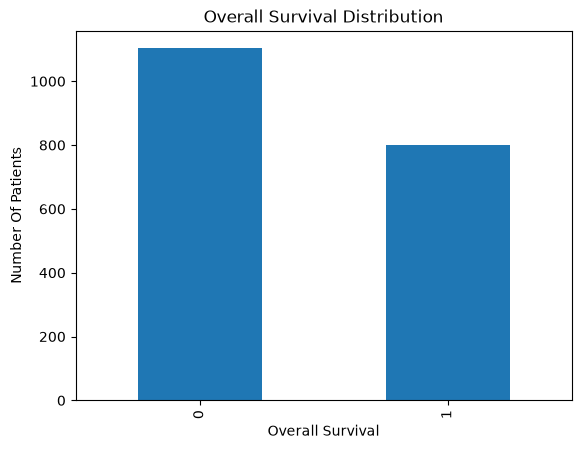

In [13]:
df['overall_survival'].value_counts().plot(kind='bar')

plt.title('Overall Survival Distribution')
plt.xlabel('Overall Survival')
plt.ylabel('Number Of Patients')

plt.show()

In [14]:
print(
    df[['overall_survival',
        'overall_survival_months',
        'death_from_cancer']].head(20)
    
)

    overall_survival  overall_survival_months     death_from_cancer
0                  1               140.500000                Living
1                  1                84.633333                Living
2                  0               163.700000       Died of Disease
3                  1               164.933333                Living
4                  0                41.366667       Died of Disease
5                  0                 7.800000       Died of Disease
6                  1               164.333333                Living
7                  0                99.533333  Died of Other Causes
8                  0                36.566667  Died of Other Causes
9                  0                36.266667       Died of Disease
10                 0               132.033333       Died of Disease
11                 1               163.533333                Living
12                 1               164.900000                Living
13                 0                14.133333  D

In [15]:
pd.crosstab(
    df['overall_survival'],
    df['death_from_cancer'],
    dropna=False
)

death_from_cancer,Died of Disease,Died of Other Causes,Living,NaN
overall_survival,,,,
0,622,480,0,1
1,0,0,801,0


In [16]:
print(df['overall_survival'].value_counts(dropna=False))

overall_survival
0    1103
1     801
Name: count, dtype: int64


In [17]:
print(df['overall_survival_months'].describe())

count    1904.000000
mean      125.121324
std        76.334148
min         0.000000
25%        60.825000
50%       115.616667
75%       184.716667
max       355.200000
Name: overall_survival_months, dtype: float64


In [18]:
print(df['death_from_cancer'].value_counts(dropna=False))

death_from_cancer
Living                  801
Died of Disease         622
Died of Other Causes    480
NaN                       1
Name: count, dtype: int64


In [19]:
df['time'] = df['overall_survival_months']

df['event'] = (df['overall_survival'] == 0).astype(int)

C:\Users\DANISH LAPTOP\AppData\Local\Temp\ipykernel_884\1515331965.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['time'] = df['overall_survival_months']
C:\Users\DANISH LAPTOP\AppData\Local\Temp\ipykernel_884\1515331965.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['event'] = (df['overall_survival'] == 0).astype(int)


In [20]:
print(df[['overall_survival', 'time', 'event']].head(20))

print("\nEvent Counts:")
print(df['event'].value_counts(dropna=False))

print("\nMissing Values:")
print(df[['time', 'event']].isnull().sum())

print("\nInvalid Survival Times:")
print((df['time'] < 0).sum())

    overall_survival        time  event
0                  1  140.500000      0
1                  1   84.633333      0
2                  0  163.700000      1
3                  1  164.933333      0
4                  0   41.366667      1
5                  0    7.800000      1
6                  1  164.333333      0
7                  0   99.533333      1
8                  0   36.566667      1
9                  0   36.266667      1
10                 0  132.033333      1
11                 1  163.533333      0
12                 1  164.900000      0
13                 0   14.133333      1
14                 1  103.833333      0
15                 1   75.333333      0
16                 1  161.066667      0
17                 1  160.300000      0
18                 1   62.866667      0
19                 1  140.866667      0

Event Counts:
event
1    1103
0     801
Name: count, dtype: int64

Missing Values:
time     0
event    0
dtype: int64

Invalid Survival Times:
0


In [21]:
print("Event Counts:")
print(df['event'].value_counts().sort_index())

print("\nMissing Values:")
print(df[['time', 'event']].isnull().sum())

print("\nNegative Survival Times:")
print((df['time'] < 0).sum())

print("\nZero Survival Times:")
print((df['time'] == 0).sum())

print("\nUnique Event Values:")
print(df['event'].unique())



Event Counts:
event
0     801
1    1103
Name: count, dtype: int64

Missing Values:
time     0
event    0
dtype: int64

Negative Survival Times:
0

Zero Survival Times:
1

Unique Event Values:
[0 1]


In [23]:
pip install lifelines

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
    --------------------------------------- 0.3/11.0 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.0 MB 1.9 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/11.0 MB 2.2 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/11.0 MB 2.4 MB/s eta 0:00:04
   --------- ------------------------------ 2.6/11.0 MB 2.6 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/11.0 MB 2.7 MB/s eta 0:00:03
   ------------- -------------------------- 3.7/11.0 MB 2.5 MB/s eta 0:00:03
   --------------- ------------------------ 4.2/11.0 MB 2.6 MB/s eta

  You can safely remove it manually.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from lifelines import KaplanMeierFitter

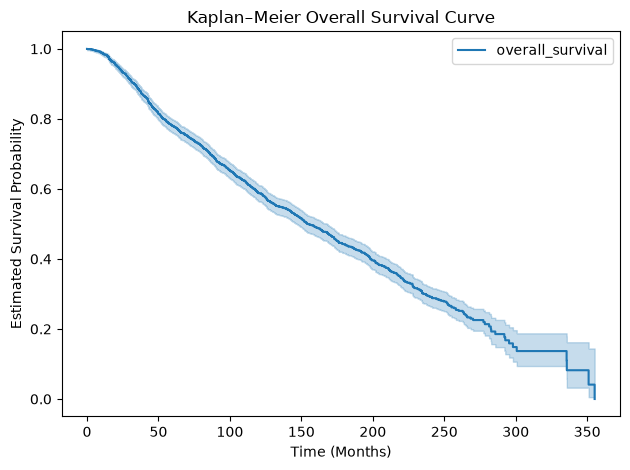

In [26]:
kmf = KaplanMeierFitter()

kmf.fit(
    durations=df['time'],
    event_observed=df['event'],
    label='overall_survival'
)

kmf.plot_survival_function()

plt.title('Kaplan–Meier Overall Survival Curve')
plt.xlabel('Time (Months)')
plt.ylabel('Estimated Survival Probability')
plt.tight_layout()
plt.show()


In [28]:
df.loc[
    df['time'] == 0,
    ['overall_survival', 'overall_survival_months', 'death_from_cancer']
]

,overall_survival,overall_survival_months,death_from_cancer
170,1,0.0,Living


In [29]:
df.loc[
    df['overall_survival_months'] == 0,
    [
        'patient_id',
        'overall_survival',
        'overall_survival_months',
        'death_from_cancer'
    ]
]

,patient_id,overall_survival,overall_survival_months,death_from_cancer
170,284,1,0.0,Living
